In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import json
import joblib

from scipy.stats import randint
from functools import partial

from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import make_scorer, ndcg_score
from sklearn.model_selection import RandomizedSearchCV, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures

import sys
from pathlib import Path

In [2]:
pd.set_option('display.max_columns', None)

ROOT = Path.cwd()
while not (ROOT / ".git").exists() and ROOT != ROOT.parent:
     ROOT = ROOT.parent
src_path = str(ROOT/"src")
if src_path not in sys.path:
    sys.path.insert(0,src_path)

from config import START_YEAR, END_YEAR, HOLDOUT_START
import utils
from final_model import ClassifiedRegressor

In [3]:
df = utils.player_stat_dataframe(START_YEAR,END_YEAR)

train = df[df.Year < HOLDOUT_START]
test = df[df.Year >= HOLDOUT_START]

req = ['Year', 'GP%', 'MP']
f = ['PTS','W%','DRB','AST','BLK','STL','FT','3P','eFG%']
features = list(set(req + f))

target = 'MVPVS'

In [4]:
X_tr, y_tr = train[features], train[target]

cv = list(utils.forward_chaining_splits(X_tr.Year, min_train_years=10))

def ndcg_at_1(y_true, y_pred):
    return ndcg_score(np.asarray(y_true).reshape(1, -1),
                      np.asarray(y_pred).reshape(1, -1), k=1)

ndcg1_scorer = make_scorer(ndcg_at_1)

base = ClassifiedRegressor(
    classifier=make_pipeline(
        PolynomialFeatures(degree=2), 
        StandardScaler(),
        LogisticRegression(solver='saga', max_iter=1000, random_state=97, tol=1e-3)),
    regressor=HistGradientBoostingRegressor(random_state=29),
)

search = RandomizedSearchCV(
    base,
    param_distributions={
        'classifier__logisticregression__C': np.logspace(-2, 1, 5),
        'classifier__logisticregression__l1_ratio': [0, 0.25, 0.5, 0.75, 1],
        'threshold': [0.1, 0.3, 0.5, 0.7, 0.9],
        'regressor__loss': ['squared_error', 'poisson'],
        'regressor__learning_rate': [0.01, 0.03, 0.05],
        'regressor__max_iter': [100, 200, 300, 400, 500],
        'regressor__max_depth': [2, 3, 4, None],
        'regressor__max_leaf_nodes': [7, 15, 31],
        'regressor__min_samples_leaf': [1, 2, 3, 4, 5],
        'regressor__l2_regularization': [0.0, 0.5, 1.0],
    },
    n_iter=100, cv=cv, scoring=ndcg1_scorer, n_jobs=-1, random_state=29,
)
search.fit(X_tr, y_tr)
print(f'Best parameters:')
print(search.best_params_)

model = search.best_estimator_


Best parameters:
{'threshold': 0.1, 'regressor__min_samples_leaf': 1, 'regressor__max_leaf_nodes': 15, 'regressor__max_iter': 200, 'regressor__max_depth': None, 'regressor__loss': 'squared_error', 'regressor__learning_rate': 0.01, 'regressor__l2_regularization': 0.0, 'classifier__logisticregression__l1_ratio': 0.5, 'classifier__logisticregression__C': np.float64(0.01)}


In [9]:
X_tr, y_tr = train[features], train[target]

tot = 0
fin = pd.DataFrame()
cv = list(utils.forward_chaining_splits(X_tr.Year, min_train_years=10))
for chain in cv:
    model = ClassifiedRegressor(
        classifier=make_pipeline(
        PolynomialFeatures(degree=2), 
        StandardScaler(),
        LogisticRegression(solver='saga', max_iter=1000, random_state=97, tol=1e-3)),
    regressor=HistGradientBoostingRegressor(random_state=29),
    )
    model = search.best_estimator_
    model.fit(X_tr.iloc[chain[0]], y_tr.iloc[chain[0]])
    res = train.iloc[chain[1]]
    res['Output'] = model.predict(X_tr.iloc[chain[1]])
    pred_winner = res.sort_values('Output', ascending=False).Player.iloc[:3].to_numpy()
    actual_winner = res.sort_values('MVPVS', ascending=False).Player.iloc[0]
    tot += (pred_winner[0] == actual_winner)
    fin = pd.concat([fin,pd.DataFrame({'Year':[res.Year.iloc[0]], 
                                       'Actual':[actual_winner], 
                                       'Predicted': [pred_winner], 
                                       'Top3': [(pred_winner == actual_winner).any()],
                                       'Match': [(pred_winner[0] == actual_winner)]})]
                    )

print(f'{tot}/{len(cv)}')
fin

28/35


,Year,Actual,Predicted,Top3,Match
0,1990,Michael Jordan,"[Michael Jordan, Magic Johnson, Karl Malone]",True,True
0,1991,Michael Jordan,"[Michael Jordan, Clyde Drexler, Chris Mullin]",True,True
0,1992,Charles Barkley,"[Charles Barkley, Patrick Ewing, Michael Jordan]",True,True
0,1993,Hakeem Olajuwon,"[Hakeem Olajuwon, David Robinson, Shaquille O'...",True,True
0,1994,David Robinson,"[David Robinson, Karl Malone, Hakeem Olajuwon]",True,True
0,1995,Michael Jordan,"[Michael Jordan, Karl Malone, David Robinson]",True,True
0,1996,Karl Malone,"[Michael Jordan, Karl Malone, Grant Hill]",True,False
0,1997,Michael Jordan,"[Michael Jordan, Shaquille O'Neal, Karl Malone]",True,True
0,1998,Karl Malone,"[Karl Malone, Allen Iverson, Shaquille O'Neal]",True,True
0,1999,Shaquille O'Neal,"[Shaquille O'Neal, Karl Malone, Kobe Bryant]",True,True


In [7]:
X_te, y_te = test[features], test[target]

tot = 0
fin = pd.DataFrame()
cv = list(utils.forward_chaining_splits(df.Year, min_train_years=10))[-len(test.Year.unique()):]
for chain in cv:
    model = search.best_estimator_
    model = ClassifiedRegressor(
            classifier=make_pipeline(
            PolynomialFeatures(degree=2), 
            StandardScaler(),
            LogisticRegression(solver='saga', max_iter=1000, random_state=97, tol=1e-3)),
        regressor=HistGradientBoostingRegressor(random_state=29),
        )
    model = search.best_estimator_
    model.fit(df[features].iloc[chain[0]], df[target].iloc[chain[0]])
    res = test.loc[chain[1]]
    res['Output'] = model.predict(df[features].iloc[chain[1]])
    pred_winner = res.sort_values('Output', ascending=False).Player.iloc[:3].to_numpy()
    actual_winner = res.sort_values('MVPVS', ascending=False).Player.iloc[0]
    tot += (pred_winner[0] == actual_winner)
    fin = pd.concat([fin,pd.DataFrame({'Year':[res.Year.iloc[0]], 
                                        'Actual':[actual_winner], 
                                        'Predicted': [pred_winner], 
                                        'Top3': [(pred_winner == actual_winner).any()],
                                        'Match': [(pred_winner[0] == actual_winner)]})]
    )

print(f'{tot}/{len(cv)}')
fin

1/1


,Year,Actual,Predicted,Top3,Match
0,2025,Shai Gilgeous-Alexander,"[Shai Gilgeous-Alexander, Nikola Jokić, Cade C...",True,True


# Visuals
The tuned model is rebuilt from the best settings found by the search above, so the search doesn't need to rerun. Each season is predicted by a fresh copy of the model trained only on earlier seasons; 2025–26 is the test season.

In [4]:
# tuned model with fixed settings
from sklearn.base import clone

#best settings from the search above (copied from its printed output)
# Best parameters:
#{'threshold': 0.1, 
# 'regressor__min_samples_leaf': 1, 
# 'regressor__max_leaf_nodes': 15, 
# 'regressor__max_iter': 200, 
# 'regressor__max_depth': None, 
# 'regressor__loss': 'squared_error', 
# 'regressor__learning_rate': 0.01, 
# 'regressor__l2_regularization': 0.0, 
# 'classifier__logisticregression__l1_ratio': 0.5, 
# 'classifier__logisticregression__C': np.float64(0.01)}

tuned = ClassifiedRegressor(
    classifier=make_pipeline(
        PolynomialFeatures(degree=2),
        StandardScaler(),
        LogisticRegression(solver='saga', max_iter=1000, random_state=97, tol=1e-3, C=0.01, l1_ratio=0.5)),
    regressor=HistGradientBoostingRegressor(random_state=29, loss='squared_error', learning_rate=0.01, max_iter=200,
                                            max_depth=None, max_leaf_nodes=15, min_samples_leaf=1, l2_regularization=0.0),
    threshold=0.1,
)

OUT = ROOT / 'results'                  #final charts and tables
OUT.mkdir(parents=True, exist_ok=True)

In [ ]:
def evaluate_seasons(model, data, seasons):
    """For each season: fit a fresh copy of the tuned model on all earlier seasons, then predict that season.
    Returns (one row per season, every player's prediction)."""
    rows, preds = [], []
    for yr in seasons:
        tr, te = data[data['Year'] < yr], data[data['Year'] == yr]
        m = clone(model).fit(tr[features], tr[target])
        res = te.assign(Output=m.predict(te[features]))
        preds.append(res)
        ranked = res.sort_values('Output', ascending=False)
        top3 = ranked['Player'].iloc[:3].tolist()
        actual = res.sort_values('MVPVS', ascending=False)['Player'].iloc[0]
        actual_pred = res.loc[res['Player'] == actual, 'Output'].iloc[0]
        rank = ranked['Player'].tolist().index(actual) + 1
        predicted_something = ranked['Output'].iloc[0] > 0                 #all zeros = the model made no pick
        rows.append({'Year': yr, 'Actual': actual, 'Predicted': top3[0] if predicted_something else '(no pick)',
                     'Top3': top3, 'flagged': int((res['Output'] > 0).sum()),
                     'Match': predicted_something and top3[0] == actual,
                     'In top 3': actual_pred > 0 and rank <= 3, 'MVP rank': rank})
    return pd.DataFrame(rows), pd.concat(preds)

fin_dev, preds_dev = evaluate_seasons(tuned, df, range(1990, HOLDOUT_START))          #1990-2024 (seasons used for tuning)
fin_test, preds_test = evaluate_seasons(tuned, df, range(HOLDOUT_START, END_YEAR + 1)) #2025
print(f"1990-{HOLDOUT_START - 1}: {fin_dev['Match'].sum()}/{len(fin_dev)} MVPs, top 3 in {fin_dev['In top 3'].sum()}/{len(fin_dev)}")
print(f"{HOLDOUT_START}: {fin_test['Match'].sum()}/{len(fin_test)}")
print('fewest players flagged in a season:', pd.concat([fin_dev, fin_test])['flagged'].min())

1990-2024: 28/35 MVPs, top 3 in 33/35
2025: 1/1
fewest players flagged in a season: 28


In [6]:
pd.concat([fin_dev, fin_test]).to_csv(OUT / 'season_results.csv', index=False)
fin_dev[~fin_dev['Match']]          #the 7 seasons the model missed

,Year,Actual,Predicted,Top3,flagged,Match,In top 3,MVP rank
6,1996,Karl Malone,Michael Jordan,"[Michael Jordan, Karl Malone, Grant Hill]",40,False,True,2
12,2002,Tim Duncan,Dirk Nowitzki,"[Dirk Nowitzki, Kobe Bryant, Tim Duncan]",37,False,True,3
14,2004,Steve Nash,Amar'e Stoudemire,"[Amar'e Stoudemire, Allen Iverson, Dirk Nowitzki]",35,False,False,15
15,2005,Steve Nash,LeBron James,"[LeBron James, Kobe Bryant, Steve Nash]",38,False,True,3
16,2006,Dirk Nowitzki,Steve Nash,"[Steve Nash, Dirk Nowitzki, Kobe Bryant]",36,False,True,2
26,2016,Russell Westbrook,Kevin Durant,"[Kevin Durant, Stephen Curry, Kawhi Leonard]",38,False,False,4
32,2022,Joel Embiid,Giannis Antetokounmpo,"[Giannis Antetokounmpo, Joel Embiid, Jayson Ta...",29,False,True,2


In [7]:
#chart styling
SURFACE, INK, INK2, MUTED, GRID, AXIS = '#fcfcfb', '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7'
BLUE, ORANGE = '#2a78d6', '#eb6834'

def new_chart(figsize):
    fig, ax = plt.subplots(figsize=figsize, dpi=200)
    fig.patch.set_facecolor(SURFACE); ax.set_facecolor(SURFACE)
    for side in ['top', 'right', 'left']:
        ax.spines[side].set_visible(False)
    ax.spines['bottom'].set_color(AXIS)
    ax.tick_params(colors=MUTED, length=0)
    return fig, ax

def add_titles(fig, main, sub):
    fig.text(0.02, 0.96, main, fontsize=14, fontweight='bold', color=INK, va='top')
    fig.text(0.02, 0.89, sub, fontsize=10.5, color=INK2, va='top')

def season_label(y):
    return f"{y}–{str(y + 1)[-2:]}"

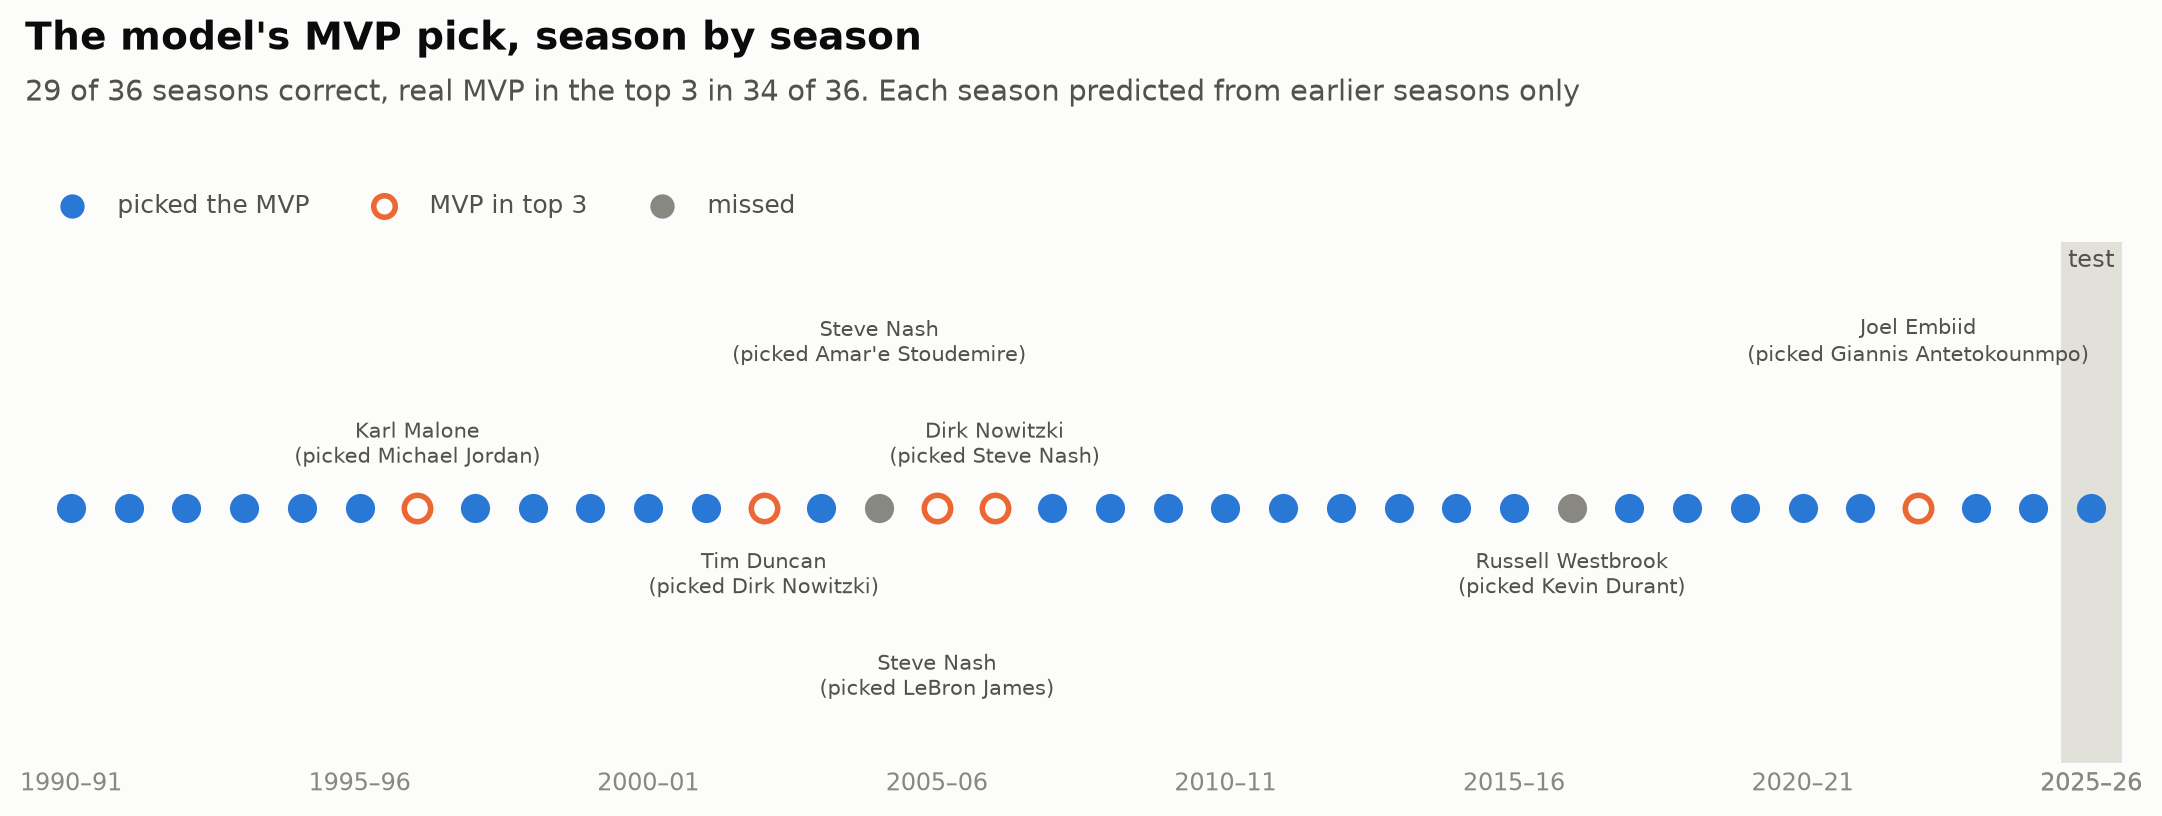

In [13]:
#season by season
def plot_seasons(results, fname):
    """One dot per season: blue = picked the MVP, orange ring = MVP in the top 3, gray = missed. Misses are labeled."""
    fig, ax = new_chart((11, 4.2))
    ax.set_yticks([]); ax.spines['bottom'].set_visible(False)
    slots = [(0.15, 'bottom'), (-0.15, 'top'), (0.55, 'bottom'), (-0.55, 'top')]   #above near, below near, above far, below far
    k = 0
    for _, r in results.iterrows():
        x = r['Year']
        if r['Match']:
            ax.scatter(x, 0, s=90, color=BLUE, zorder=3)
        elif r['In top 3']:
            ax.scatter(x, 0, s=90, facecolor=SURFACE, edgecolor=ORANGE, linewidth=2, zorder=3)
        else:
            ax.scatter(x, 0, s=90, color=MUTED, zorder=3)
        if not r['Match']:
            y, va = slots[k % 4]
            ax.text(x, y, f"{r['Actual']}\n(picked {r['Predicted']})", ha='center', va=va,
                    fontsize=7.5, color=INK2, linespacing=1.3)
            k += 1
    ax.axvspan(HOLDOUT_START - 0.5, results['Year'].max() + 0.5, color=GRID, zorder=0)
    ax.text(results['Year'].max(), 0.95, 'test', ha='center', fontsize=8.5, color=INK2)
    ax.set_xlim(results['Year'].min() - 0.8, results['Year'].max() + 0.8)
    ax.set_ylim(-1.0, 1.05)
    ticks = [y for y in results['Year'] if y % 5 == 0] + [results['Year'].max()]
    ax.set_xticks(ticks); ax.set_xticklabels([season_label(y) for y in ticks], fontsize=8.5)
    ax.scatter([], [], s=60, color=BLUE, label='picked the MVP')
    ax.scatter([], [], s=60, facecolor=SURFACE, edgecolor=ORANGE, linewidth=2, label='MVP in top 3')
    ax.scatter([], [], s=60, color=MUTED, label='missed')
    ax.legend(loc='lower left', bbox_to_anchor=(0, 1.0), ncol=3, frameon=False, fontsize=9, labelcolor=INK2)
    n, hits, top3 = len(results), results['Match'].sum(), results['In top 3'].sum()
    add_titles(fig, "The model's MVP pick, season by season",
               f'{hits} of {n} seasons correct, real MVP in the top 3 in {top3} of {n}. '
               f'Each season predicted from earlier seasons only')
    fig.tight_layout(rect=(0, 0, 1, 0.80))
    fig.savefig(OUT / fname, facecolor=SURFACE)
    plt.show()

plot_seasons(pd.concat([fin_dev, fin_test], ignore_index=True), 'season_by_season.png')

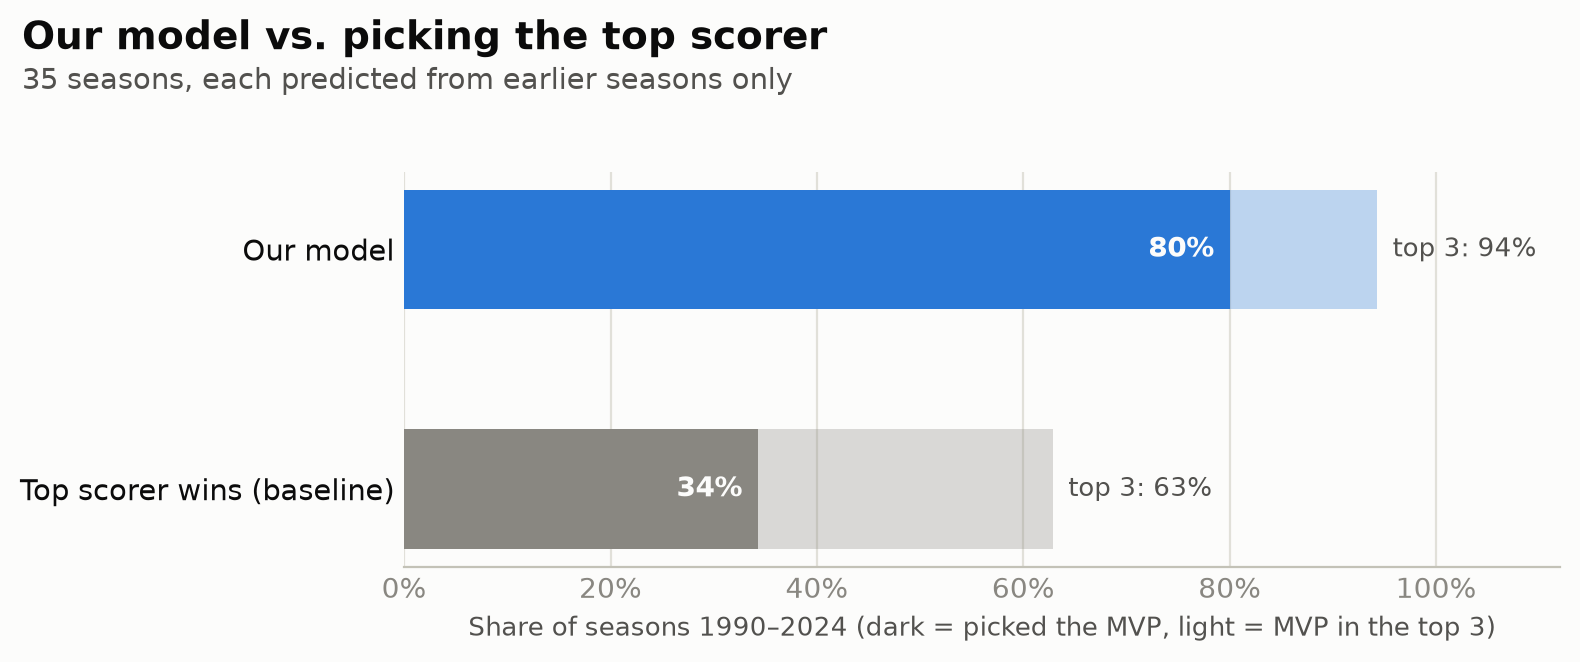

In [9]:
#model vs baseline
def baseline_hits(preds):
    """Top-scorer baseline among the players the model considers eligible."""
    hits = top3 = 0
    for _, g in preds.groupby('Year'):
        g = g[(g['GP%'] >= 0.73) & (g['MP'] >= 15)]
        order = g.sort_values('PTS', ascending=False)['Player'].tolist()
        actual = g.sort_values('MVPVS', ascending=False)['Player'].iloc[0]
        hits += order[0] == actual
        top3 += actual in order[:3]
    return hits, top3, preds['Year'].nunique()

def plot_vs_baseline(fname):
    b_hits, b_top3, n = baseline_hits(preds_dev)
    rows = [('Top scorer wins (baseline)', b_hits / n, b_top3 / n, MUTED),
            ('Our model', fin_dev['Match'].mean(), fin_dev['In top 3'].mean(), BLUE)]
    fig, ax = new_chart((8, 3.4))
    ax.xaxis.grid(True, color=GRID, linewidth=0.8); ax.set_axisbelow(True)
    for i, (lab, h, t3, col) in enumerate(rows):
        ax.barh(i, t3 * 100, height=0.5, color=col, alpha=0.3)
        ax.barh(i, h * 100, height=0.5, color=col)
        ax.text(h * 100 - 1.5, i, f'{h:.0%}', va='center', ha='right', color=SURFACE, fontsize=10, fontweight='bold')
        ax.text(t3 * 100 + 1.5, i, f'top 3: {t3:.0%}', va='center', color=INK2, fontsize=9.5)
    ax.set_yticks(range(len(rows))); ax.set_yticklabels([r[0] for r in rows], fontsize=10.5, color=INK)
    ax.set_xlim(0, 112); ax.set_xticks(range(0, 101, 20))
    ax.xaxis.set_major_formatter(lambda v, _: f'{v:.0f}%')
    ax.set_xlabel(f'Share of seasons 1990–{HOLDOUT_START - 1} (dark = picked the MVP, light = MVP in the top 3)',
                  color=INK2, fontsize=9.5)
    add_titles(fig, 'Our model vs. picking the top scorer', f'{n} seasons, each predicted from earlier seasons only')
    fig.tight_layout(rect=(0, 0, 1, 0.78))
    fig.savefig(OUT / fname, facecolor=SURFACE)
    plt.show()

plot_vs_baseline('model_vs_baseline.png')

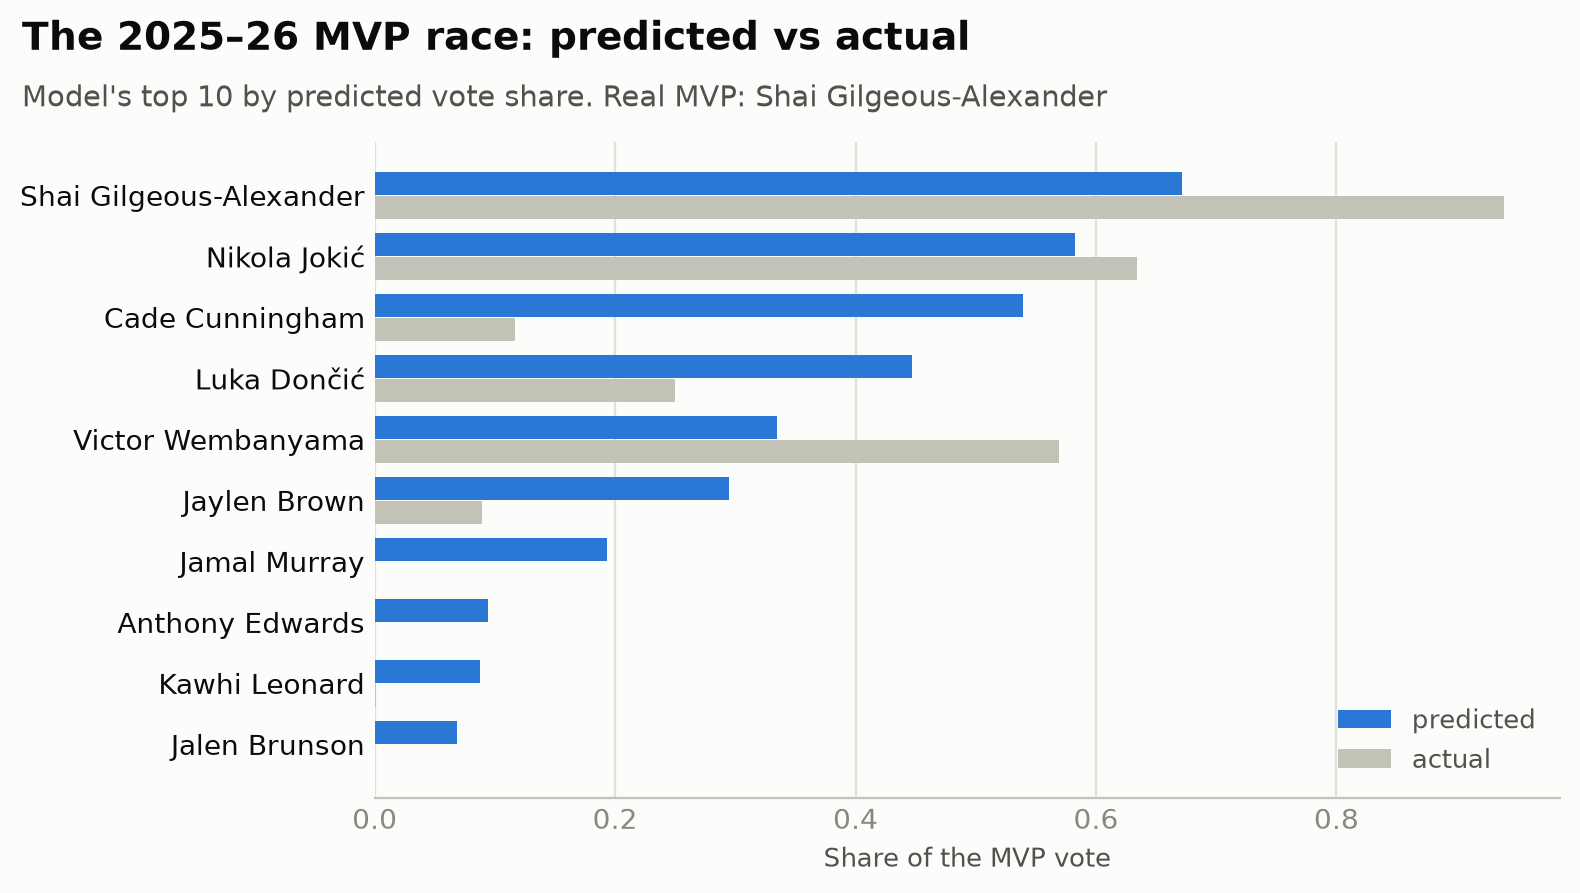

In [10]:
#test season, predicted vs actual for the model’s top 10
def plot_race(preds, year, fname, top=10):
    """Predicted vs actual vote share for the model's top players in one season."""
    g = preds[preds['Year'] == year].sort_values('Output', ascending=False).head(top).iloc[::-1]
    fig, ax = new_chart((8, 4.6))
    ax.xaxis.grid(True, color=GRID, linewidth=0.8); ax.set_axisbelow(True)
    y = np.arange(len(g))
    ax.barh(y + 0.2, g['Output'].clip(lower=0), height=0.38, color=BLUE, label='predicted')
    ax.barh(y - 0.2, g['MVPVS'], height=0.38, color=AXIS, label='actual')
    ax.set_yticks(y); ax.set_yticklabels(g['Player'], fontsize=10, color=INK)
    ax.set_xlabel('Share of the MVP vote', color=INK2, fontsize=9.5)
    ax.legend(loc='lower right', frameon=False, fontsize=9.5, labelcolor=INK2)
    mvp = preds[preds['Year'] == year].sort_values('MVPVS', ascending=False)['Player'].iloc[0]
    add_titles(fig, f'The {season_label(year)} MVP race: predicted vs actual',
               f"Model's top {top} by predicted vote share. Real MVP: {mvp}")
    fig.tight_layout(rect=(0, 0, 1, 0.86))
    fig.savefig(OUT / fname, facecolor=SURFACE)
    plt.show()

plot_race(preds_test, HOLDOUT_START, f'mvp_race_{HOLDOUT_START}.png')

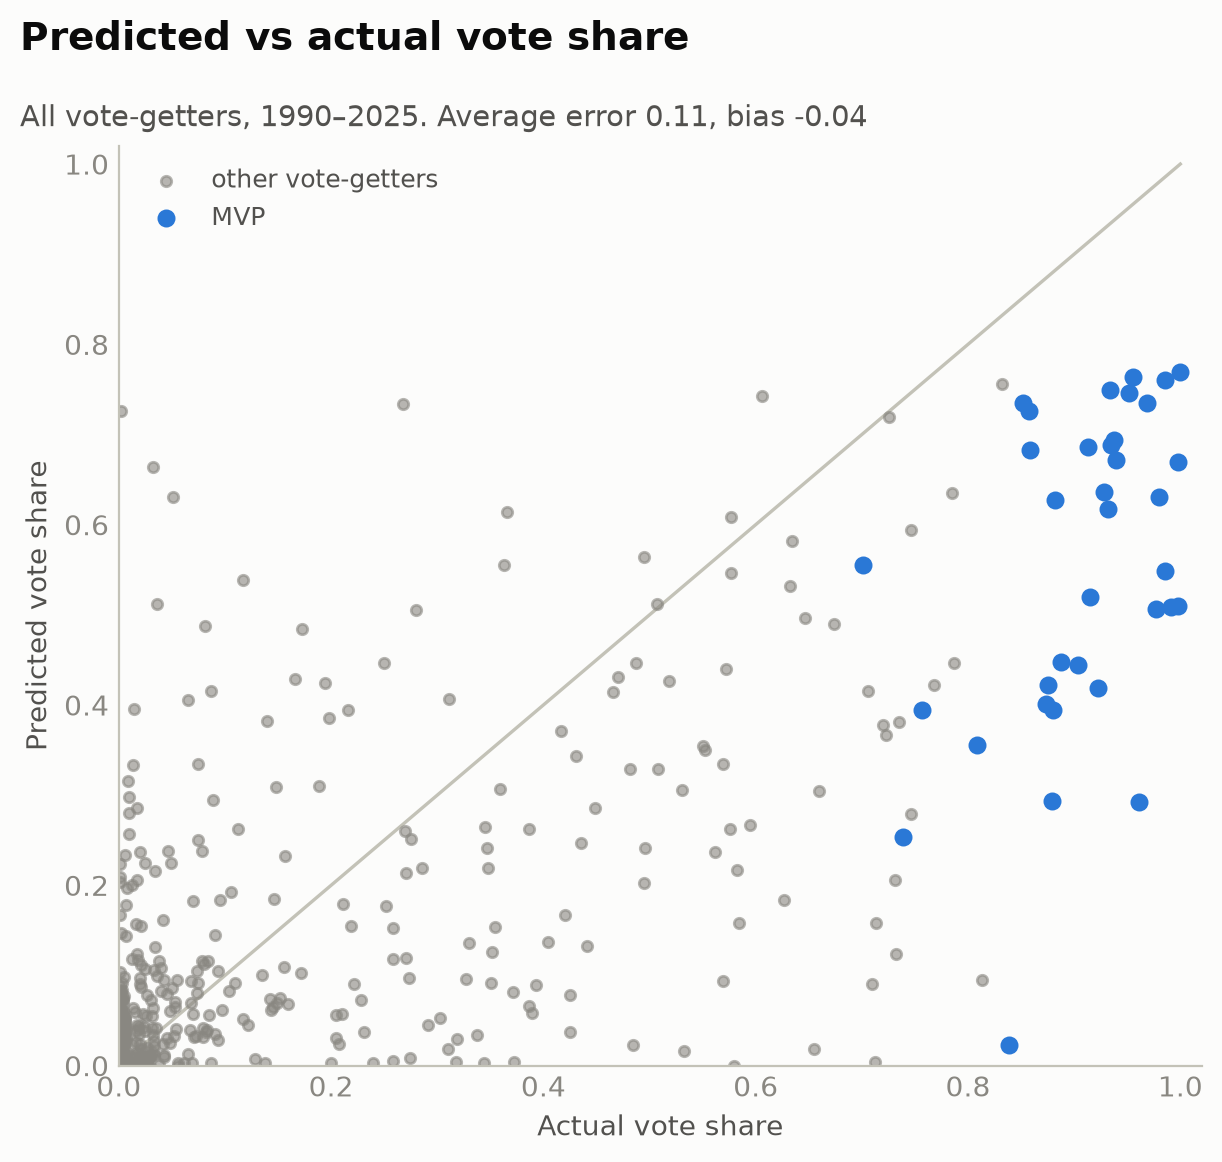

In [11]:
#predicted vs actual vote share
def plot_vote_share_fit(preds, fname):
    g = preds[preds['MVPVS'] > 0]
    fig, ax = new_chart((6.2, 6))
    ax.spines['left'].set_visible(True); ax.spines['left'].set_color(AXIS)
    ax.plot([0, 1], [0, 1], color=AXIS, linewidth=1.2, zorder=1)
    mvp = g['MVP'] == 1
    ax.scatter(g.loc[~mvp, 'MVPVS'], g.loc[~mvp, 'Output'].clip(lower=0), s=14, color=MUTED, alpha=0.6, label='other vote-getters')
    ax.scatter(g.loc[mvp, 'MVPVS'], g.loc[mvp, 'Output'].clip(lower=0), s=30, color=BLUE, label='MVP')
    ax.set_xlim(0, 1.02); ax.set_ylim(0, 1.02)
    ax.set_xlabel('Actual vote share', color=INK2); ax.set_ylabel('Predicted vote share', color=INK2)
    ax.legend(loc='upper left', frameon=False, fontsize=9, labelcolor=INK2)
    err = g['Output'].clip(lower=0) - g['MVPVS']
    add_titles(fig, 'Predicted vs actual vote share',
               f'All vote-getters, {g["Year"].min()}–{g["Year"].max()}. Average error {err.abs().mean():.2f}, bias {err.mean():+.2f}')
    fig.tight_layout(rect=(0, 0, 1, 0.88))
    fig.savefig(OUT / fname, facecolor=SURFACE)
    plt.show()

plot_vote_share_fit(pd.concat([preds_dev, preds_test]), 'vote_share_fit.png')

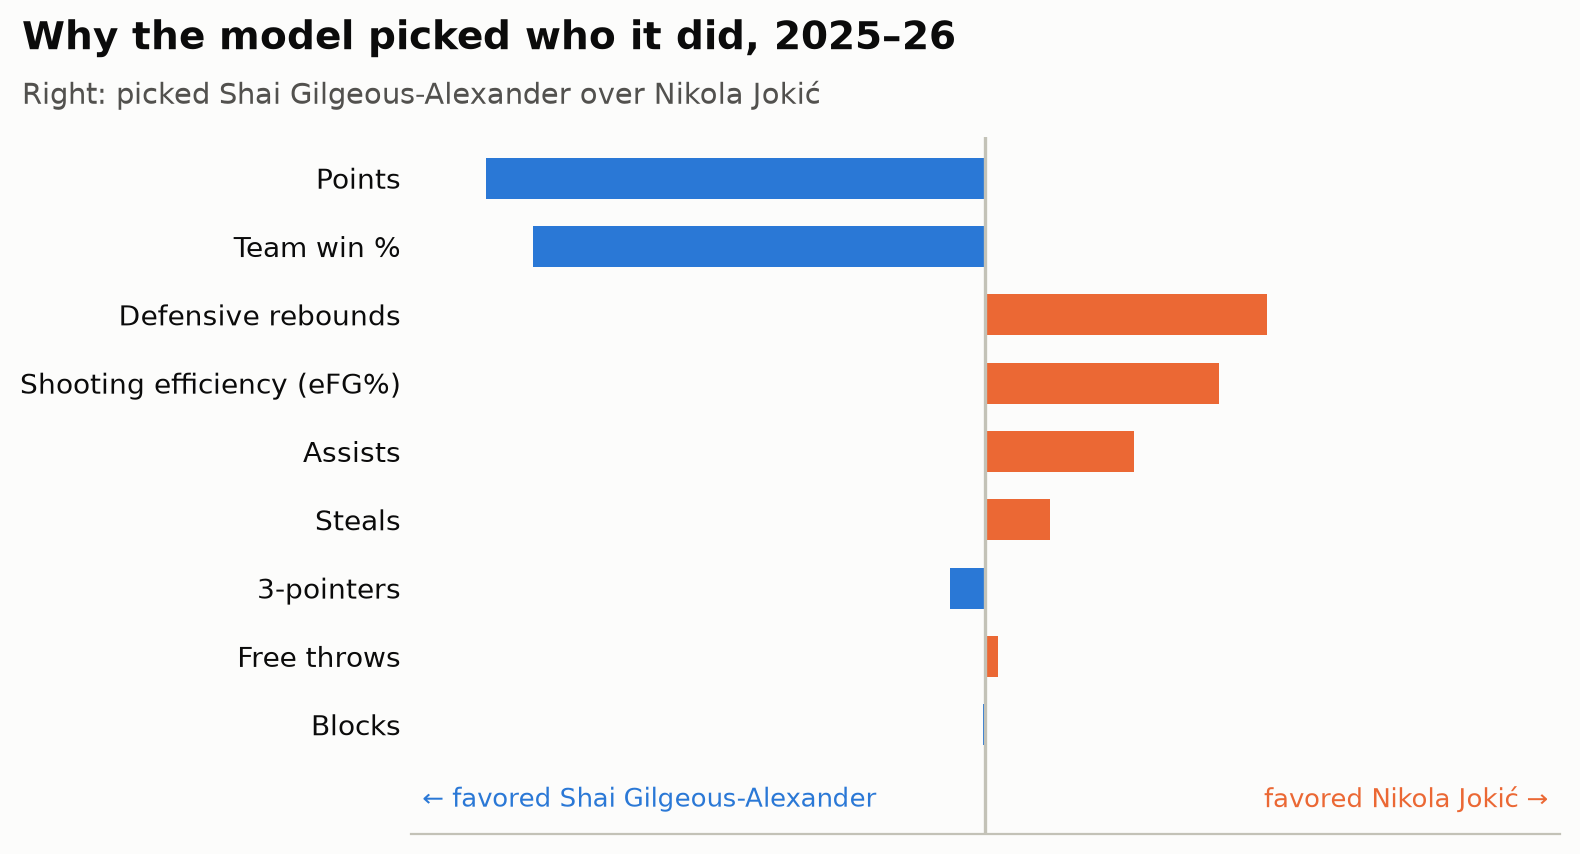

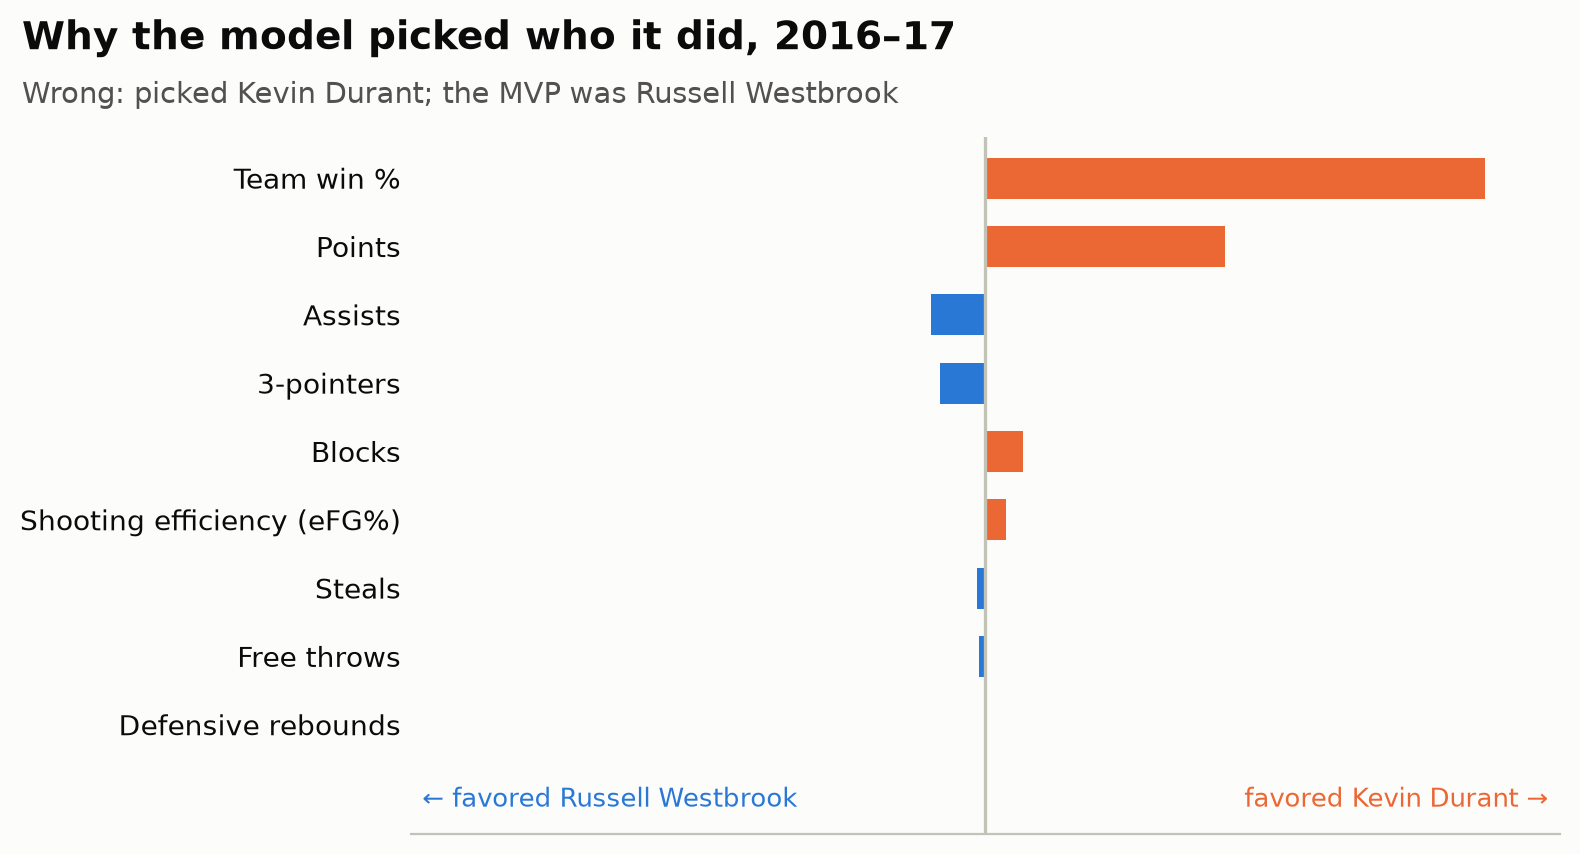

In [ ]:
#why the model picked who it did
import shap

names = {'PTS': 'Points', 'W%': 'Team win %', 'FT': 'Free throws', 'eFG%': 'Shooting efficiency (eFG%)',
         'DRB': 'Defensive rebounds', 'AST': 'Assists', 'BLK': 'Blocks', 'STL': 'Steals', '3P': '3-pointers'}
def label(c):
    return names.get(c, c)

def plot_case_final(data, model, yr, fname=None):
    """SHAP pieces of the regressor's prediction: real MVP vs the model's pick (if wrong) or runner-up (if right).
    Blue = favored the real MVP."""
    tr, te = data[data['Year'] < yr], data[data['Year'] == yr]
    m = clone(model).fit(tr[features], tr[target])
    g = te.assign(Output=m.predict(te[features])).sort_values('Output', ascending=False)
    mvp = g['MVPVS'].idxmax()
    right = g.index[0] == mvp
    other = g.index[1] if right else g.index[0]
    reg = m.regressor_
    cols = list(reg.feature_names_in_)
    vals = shap.TreeExplainer(reg).shap_values(g.loc[[mvp, other], cols])
    diff = pd.Series(vals[1] - vals[0], index=cols)          #positive = favored the other player
    diff = diff.loc[diff.abs().sort_values().index]

    fig, ax = new_chart((8, 4.4))
    ax.axvline(0, color=AXIS, linewidth=1.2)
    ax.barh(range(len(diff)), diff, height=0.6, color=[ORANGE if v > 0 else BLUE for v in diff])
    lim = diff.abs().max() * 1.15
    ax.set_xlim(-lim, lim); ax.set_xticks([])
    ax.set_yticks(range(len(diff))); ax.set_yticklabels([label(c) for c in diff.index], fontsize=10, color=INK)
    mvp_name, other_name = g.loc[mvp, 'Player'], g.loc[other, 'Player']
    ax.text(-lim * 0.98, -1.1, f'← favored {mvp_name}', color=BLUE, fontsize=9.5, va='center')
    ax.text(lim * 0.98, -1.1, f'favored {other_name} →', color=ORANGE, fontsize=9.5, va='center', ha='right')
    ax.set_ylim(-1.6, len(diff) - 0.4)
    verdict = f'Right: picked {mvp_name} over {other_name}' if right else f'Wrong: picked {other_name}; the MVP was {mvp_name}'
    add_titles(fig, f'Why the model picked who it did, {season_label(yr)}', verdict)
    fig.tight_layout(rect=(0, 0, 1, 0.86))
    fig.savefig(OUT / (fname or f'why_{yr}.png'), facecolor=SURFACE)
    plt.show()

for yr in [HOLDOUT_START, 2016]:      #the test season, and one other season where it didn't pick right (Westbrook)
    plot_case_final(df, tuned, yr)